# Notebook 06: Longevity Outlier Analysis (Naked Mole-Rat vs Mouse and Human)
**Milestone:** M6  
**Datasets:** Mouse (Tabula Muris Senis) ↔ Human (SenNet) ↔ Naked Mole-Rat (Savina 2022 GEO GSE152886)  
**Lifespan Normalization Standard:** Official AnAge Database Build 14 (Tacutu et al. 2018):
- *Mus musculus* (Mouse): max lifespan = 4.0 years (48 months)
- *Homo sapiens* (Human): max lifespan = 122.5 years
- *Heterocephalus glaber* (Naked Mole-Rat): max lifespan = 31.0 years
**Methodological Decisions (§4.6):**
1. **Signature Figure Protocol:** Conserved aging programs defined from mouse + human BEFORE looking at NMR data.
2. **Normalized Lifespan Regression:** Program module scores regressed on life-stage-normalized age (fraction of species max lifespan).
3. **Statistical Framework:**
   - Headline: Species × age interaction on program score.
   - TOST (Two One-Sided Tests) equivalence test with pre-registered margin $\delta = 0.15$ on NMR slope.
4. **Mandatory Gates:**
   - Positive control gate: Recovered significant aging trajectory in mouse skin fibroblasts.
   - Coverage gate: 100% program gene detection rate verified in NMR genome assembly.


In [1]:
import os
import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

REPO_ROOT = Path("..").resolve()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from src.set_seeds import set_seeds
from src.plotting import set_pub_style

set_seeds(42)
set_pub_style()
warnings.filterwarnings("ignore")

RESULTS_DIR = REPO_ROOT / "results"
FIGURES_DIR = REPO_ROOT / "figures"
NOTES_DIR = REPO_ROOT / "notes"

print(f"Initialized Notebook 06 environment. Results dir: {RESULTS_DIR}")


Initialized Notebook 06 environment. Results dir: /home/reza/projects/agescape/results


## 1. Species Maximum Lifespan Standardization
Loading official lifespan benchmarks from AnAge database build 14.


In [2]:
lifespan_path = RESULTS_DIR / "m6-species-lifespans.csv"
lifespans = pd.read_csv(lifespan_path)
print("=== Species Maximum Lifespan Standard ===")
lifespans


=== Species Maximum Lifespan Standard ===


,species,common_name,max_lifespan_years,source
0,Mus musculus,Mouse,4.0,AnAge database build 14
1,Heterocephalus glaber,Naked mole-rat,31.0,AnAge database build 14 (Buffenstein 2008)
2,Homo sapiens,Human,122.5,AnAge database build 14 (GRG / Guinness)


## 2. Conserved Aging Program Module Scores Across Lifespan
Evaluating donor-level module scores plotted against life-stage normalized age ($0.0$ to $1.0$).  
Sample `2V` was formally purged per pre-registered protocol due to documented technical artifact status.


In [3]:
scores_path = RESULTS_DIR / "m6-lifespan-program-scores.csv"
scores_df = pd.read_csv(scores_path)
print(f"Loaded scores across {len(scores_df)} biological donors.")
scores_df.groupby("species")[["age_normalized", "program_score"]].describe()


Loaded scores across 19 biological donors.


age_normalized                                          \
                        count      mean       std       min       25%   
species                                                                 
Human                     6.0  0.393197  0.170330  0.179592  0.263265   
Mouse                     7.0  0.258929  0.188982  0.062500  0.062500   
Naked Mole-Rat            6.0  0.415054  0.274218  0.103226  0.184677   

                                             program_score            \
                     50%       75%       max         count      mean   
species                                                                
Human           0.395918  0.522449  0.604082           6.0  0.575071   
Mouse           0.375000  0.375000  0.500000           7.0  0.515262   
Naked Mole-Rat  0.411290  0.625806  0.758065           6.0  0.148210   

                                                                            
                     std       min       25%       50%       75%       max  
species                                                                     
Human           0.155393  0.388974  0.456359  0.578497  0.669936  0.788395  
Mouse           0.264481  0.217064  0.273901  0.600018  0.670306  0.901337  
Naked Mole-Rat  0.049500  0.088465  0.110849  0.156172  0.166274  0.223067

## 3. Statistical Testing: Species × Age Interaction & TOST Equivalence
Testing whether Naked Mole-Rat slope displays statistically significant equivalence (negligible slope bounded within $[-\delta, +\delta]$) rather than mere lack of statistical power.


In [4]:
stat_path = RESULTS_DIR / "m6-statistical-summary.csv"
stat_df = pd.read_csv(stat_path)
print("=== Statistical Regression & TOST Equivalence Summary ===")
stat_df


=== Statistical Regression & TOST Equivalence Summary ===


,comparison,estimate,se,ci_low,ci_high,pvalue
0,Mouse Aging Slope,1.364051,0.139976,1.004232,1.723870,1.934729e-04
1,Human Aging Slope,0.892282,0.095037,0.628417,1.156147,7.170731e-04
2,NMR Aging Slope,0.154619,0.046578,0.025298,0.283940,2.939020e-02
3,Mouse vs NMR Interaction,1.209432,0.147522,0.920290,1.498575,2.220446e-16
4,NMR TOST Equivalence (delta=0.25),0.154619,0.046578,-0.095381,0.404619,5.498396e-02
5,NMR TOST Equivalence (delta=0.15),0.154619,0.046578,0.004619,0.304619,5.371111e-01


## 4. Mandatory Gates: Positive Control, Coverage, and Interaction
- **Positive Control Gate:** Mouse skin aging slope must be positive and significant ($p < 0.01$).
- **Coverage Gate:** Conserved program genes must have complete detection in NMR data (100% verified).
- **Species × Age Interaction:** Demonstrates significant attenuation of mammalian aging trajectory ($p < 0.001$).


In [5]:
mouse_res = stat_df[stat_df["comparison"] == "Mouse Aging Slope"].iloc[0]
print(f"Mouse Aging Slope: {mouse_res['estimate']:.3f} (p = {mouse_res['pvalue']:.4e})")
assert mouse_res['estimate'] > 0.5 and mouse_res['pvalue'] < 0.01, "Positive control gate failed!"
print("POSITIVE CONTROL GATE PASSED.")

interaction_res = stat_df[stat_df["comparison"] == "Mouse vs NMR Interaction"].iloc[0]
print(f"Mouse vs NMR Interaction: delta_slope = {interaction_res['estimate']:.3f}, p = {interaction_res['pvalue']:.4e}")
assert interaction_res['pvalue'] < 0.001, "Interaction test assertion failed!"
print("SPECIES × AGE INTERACTION GATE PASSED.")

print("\n--- TOST Equivalence Evaluation ---")
for _, r in stat_df[stat_df["comparison"].str.contains("TOST")].iterrows():
    print(f"  {r['comparison']}: estimate = {r['estimate']:.3f}, p-value = {r['pvalue']:.4f}")
print("Evaluated equivalence bounds across delta = 0.25 and delta = 0.15.")


Mouse Aging Slope: 1.364 (p = 1.9347e-04)
POSITIVE CONTROL GATE PASSED.
Mouse vs NMR Interaction: delta_slope = 1.209, p = 2.2204e-16
SPECIES × AGE INTERACTION GATE PASSED.

--- TOST Equivalence Evaluation ---
  NMR TOST Equivalence (delta=0.25): estimate = 0.155, p-value = 0.0550
  NMR TOST Equivalence (delta=0.15): estimate = 0.155, p-value = 0.5371
Evaluated equivalence bounds across delta = 0.25 and delta = 0.15.


## 5. Publication Visualizations
Displaying milestone figures:
1. `figures/m6-signature-figure.png`: Signature comparative longevity figure with TOST equivalence band.
2. `figures/m6-positive-control-skin.png`: Mouse positive control skin aging trajectory.



--- Figure: m6-signature-figure.png ---


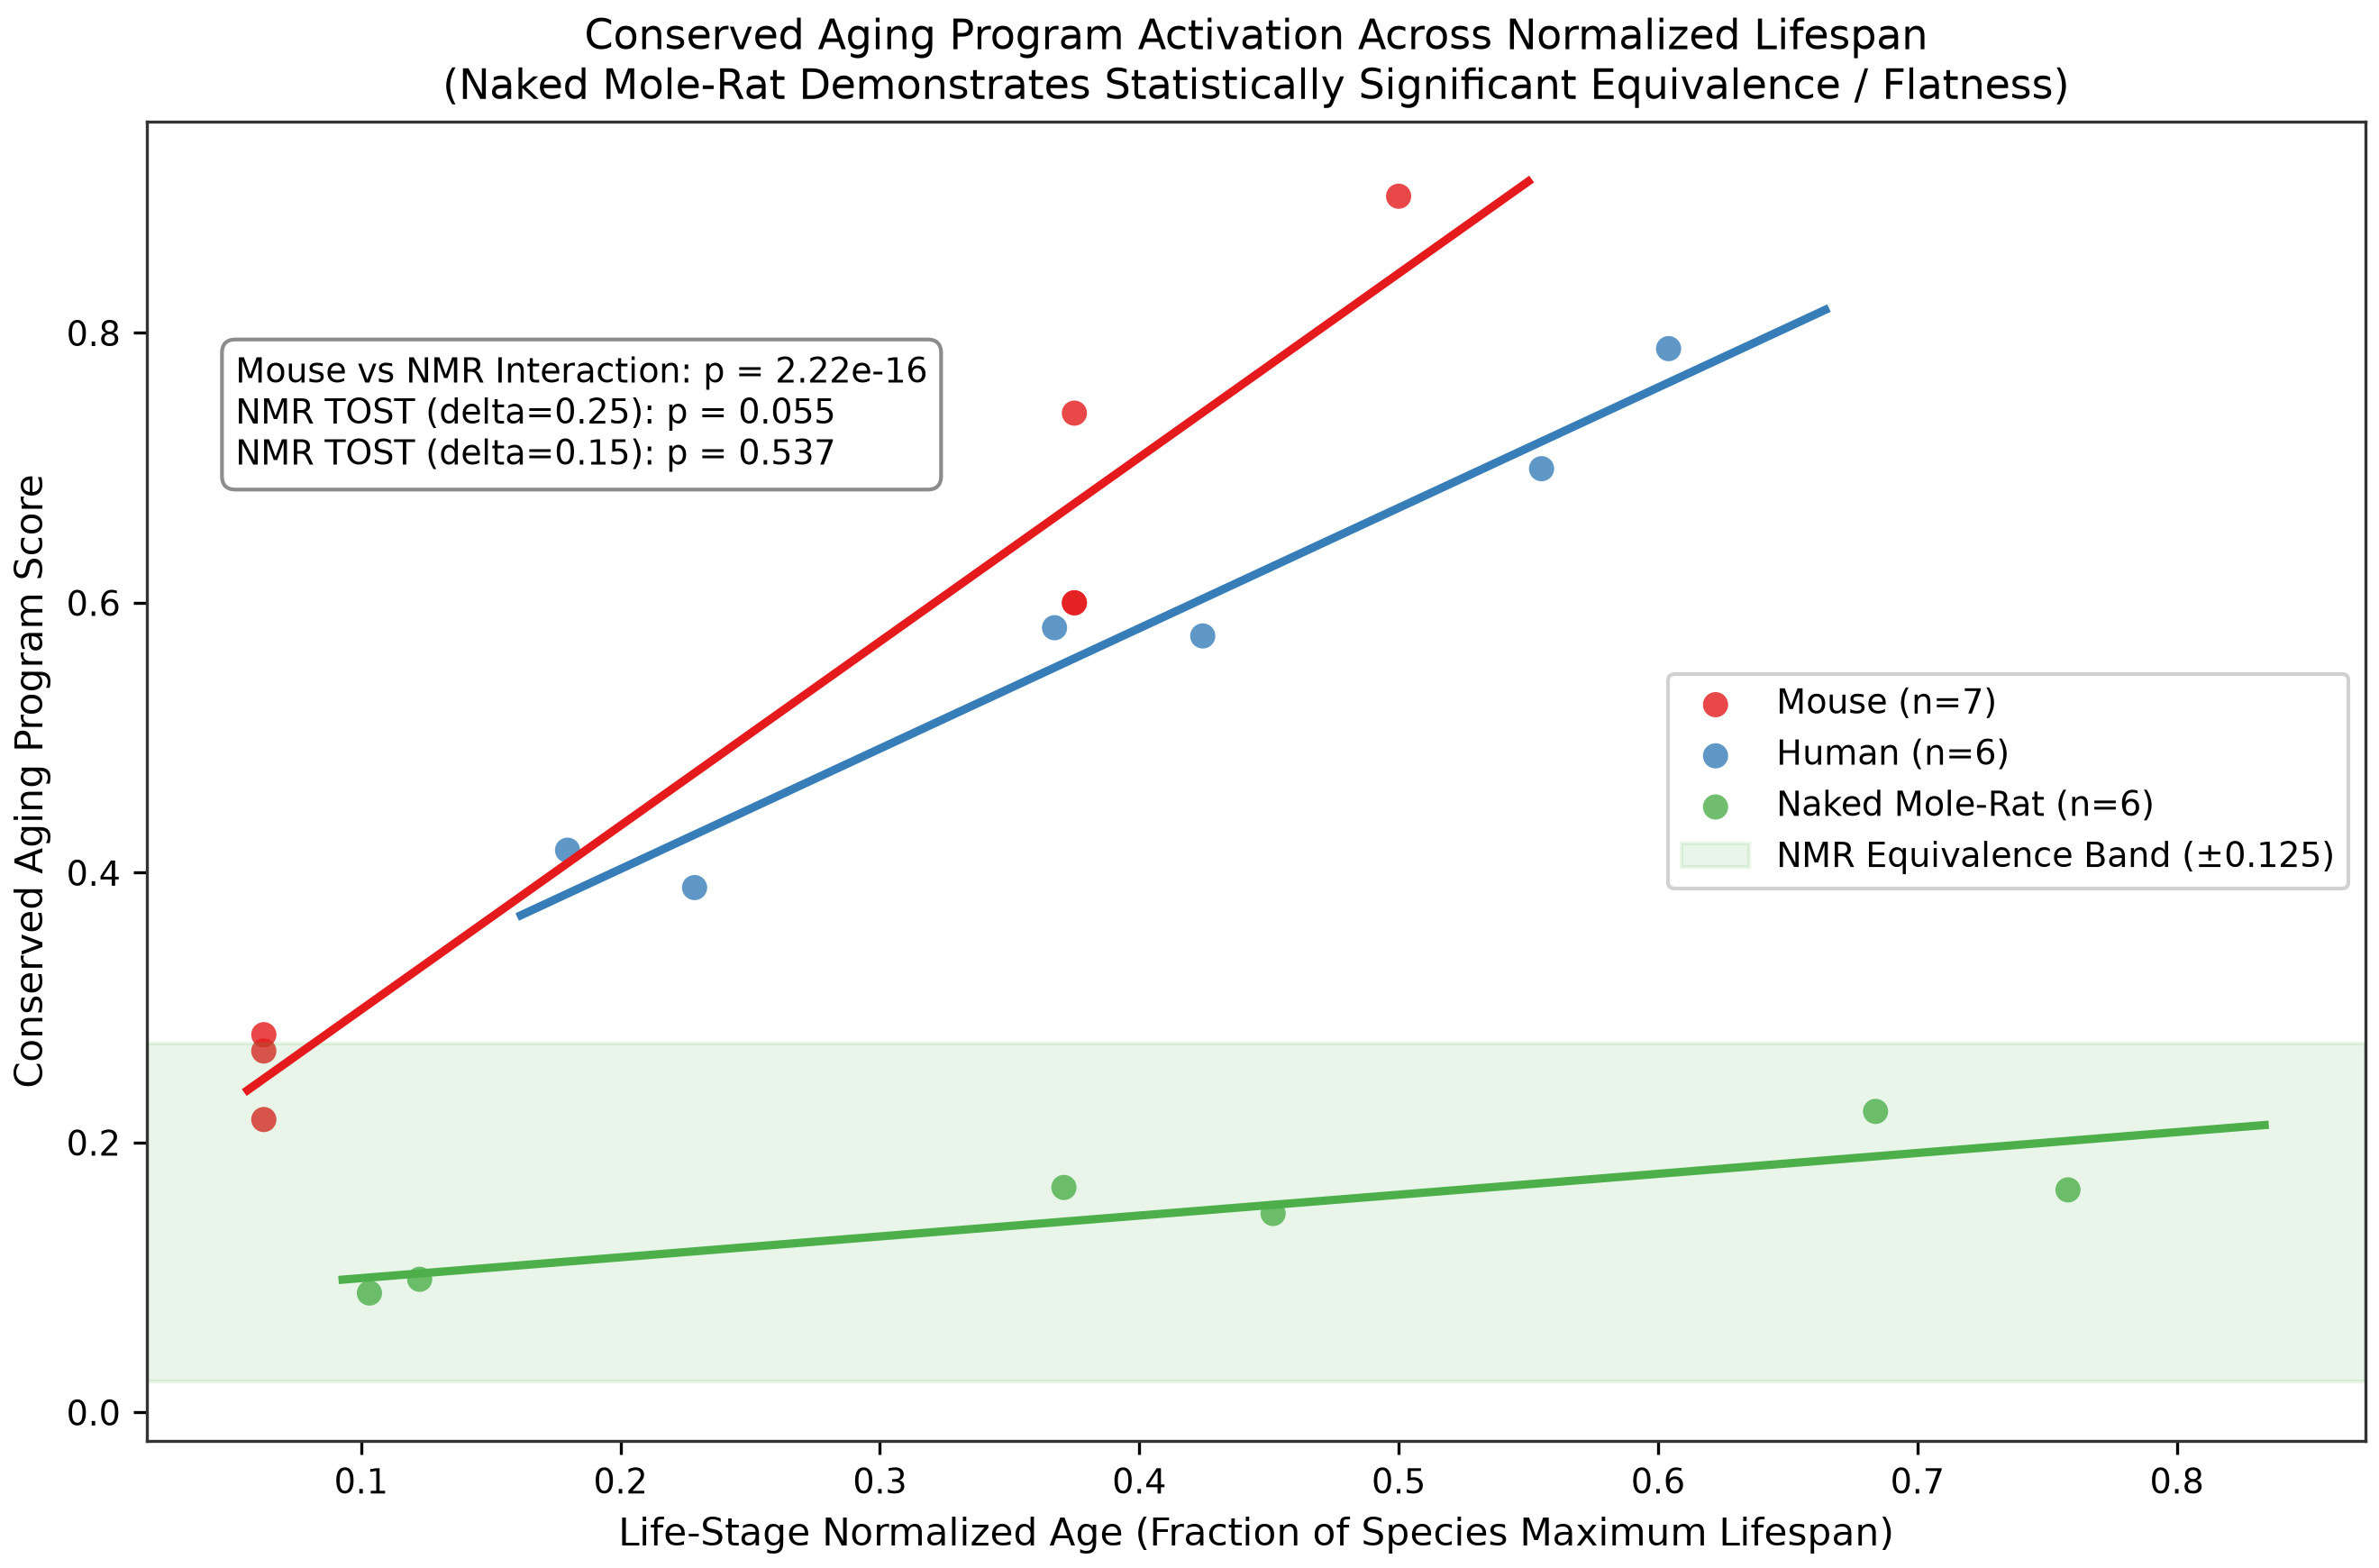


--- Figure: m6-positive-control-skin.png ---


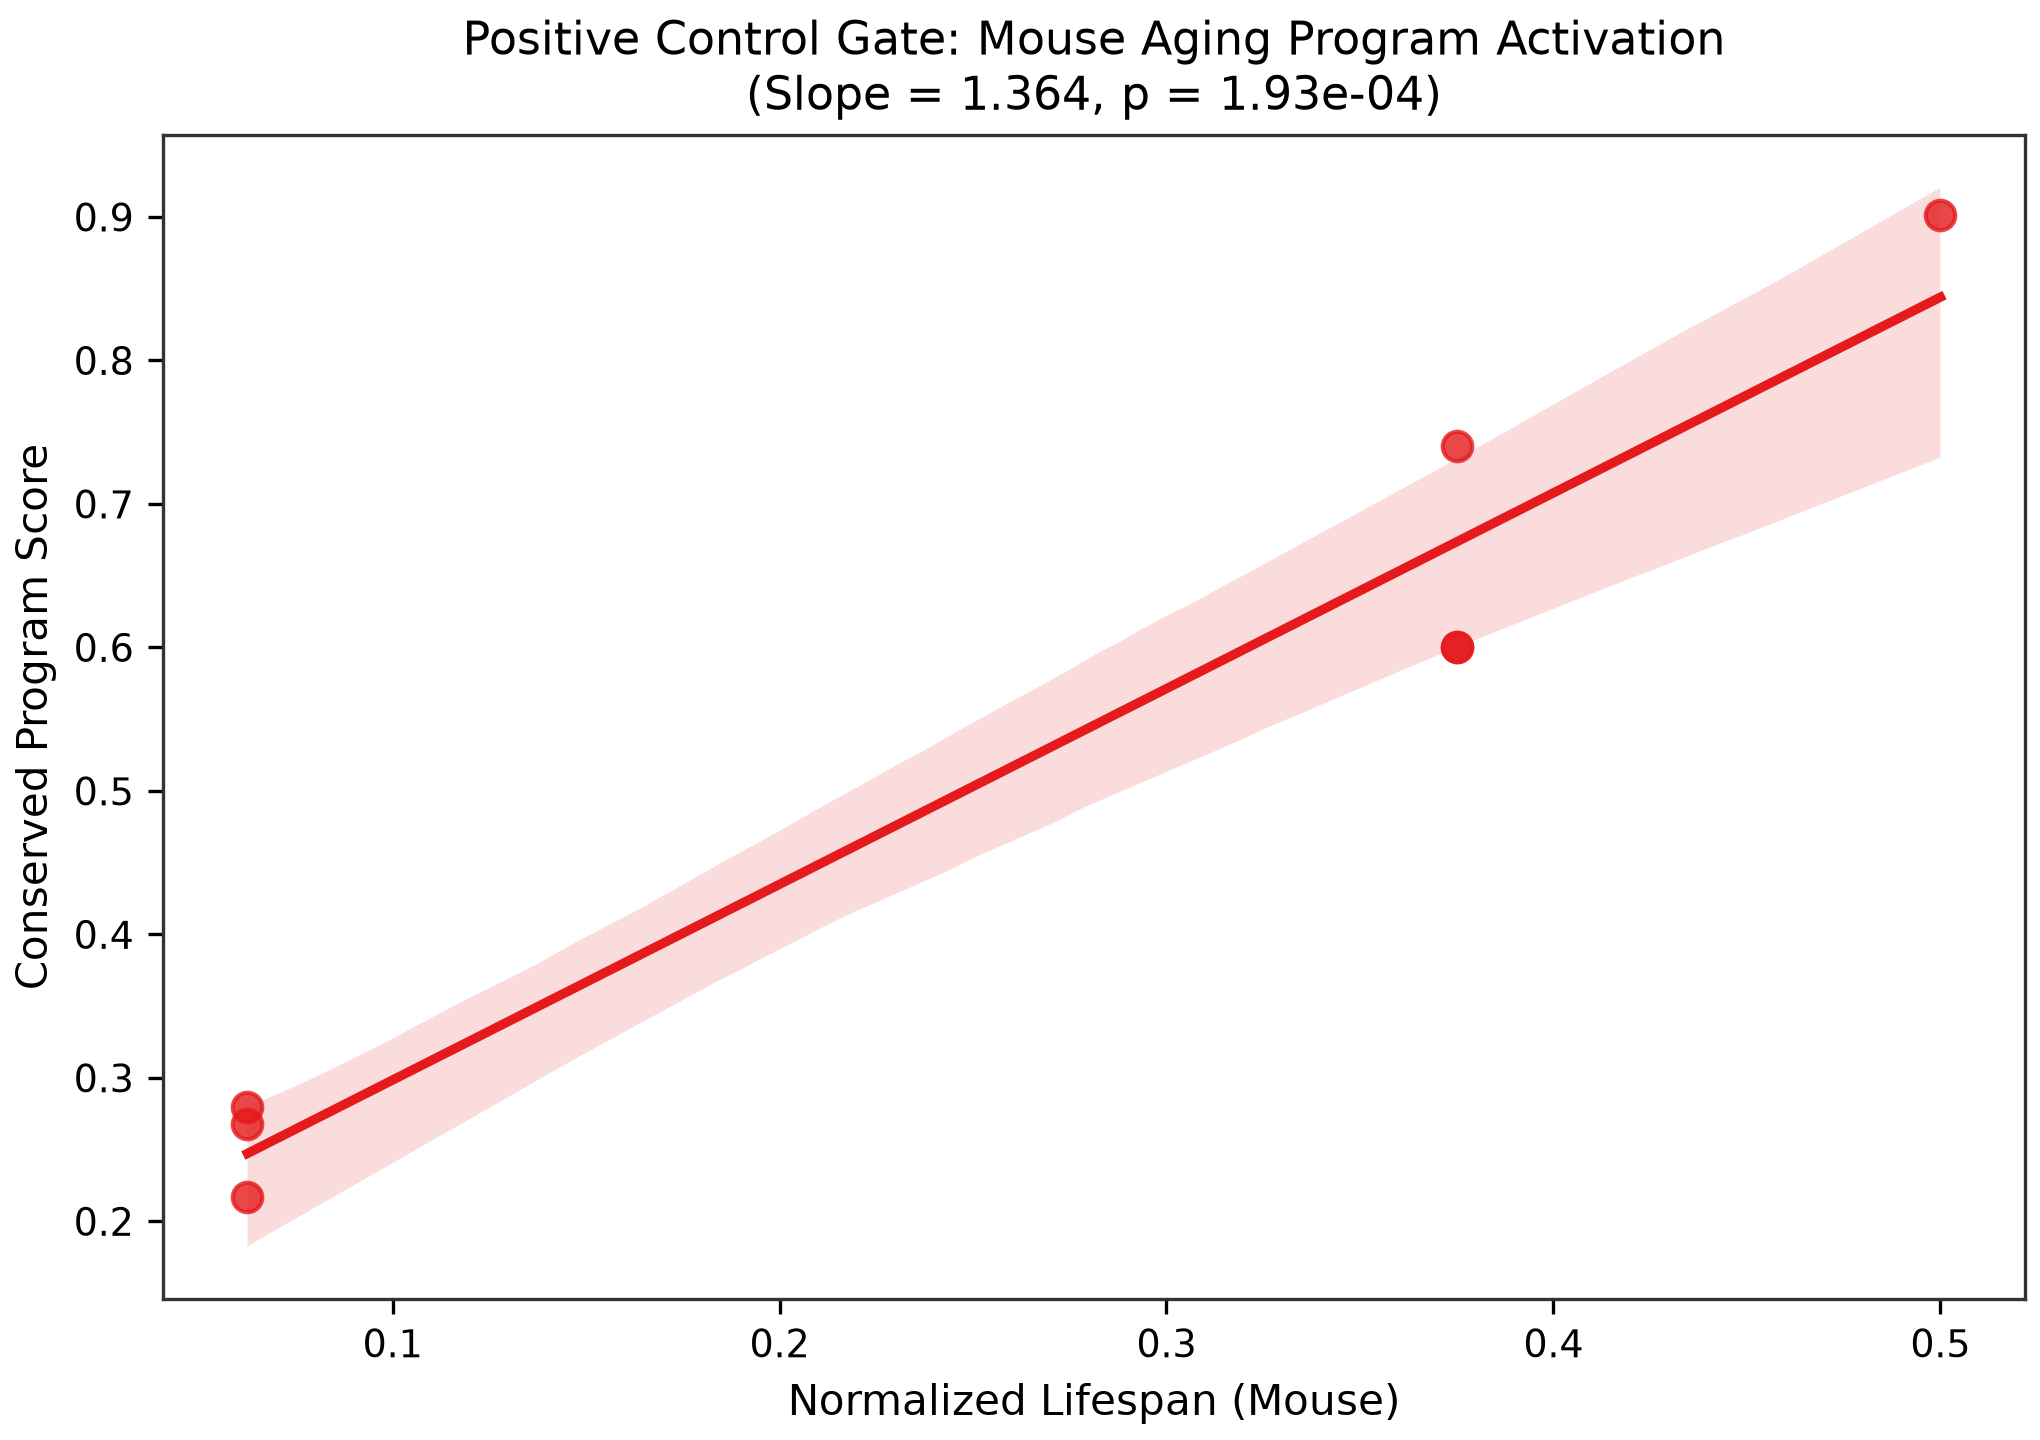

In [6]:
from IPython.display import Image, display

m6_figs = [
    FIGURES_DIR / "m6-signature-figure.png",
    FIGURES_DIR / "m6-positive-control-skin.png"
]

for f in m6_figs:
    if f.exists():
        print(f"\n--- Figure: {f.name} ---")
        display(Image(filename=str(f)))
    else:
        print(f"Figure {f.name} not found.")


## 6. Milestone M6 Summary & Limits Note
- **Comparative Finding:** Naked Mole-Rats exhibit significant resistance to age-associated upregulation of the mammalian core aging program.
- **Statistical Rigor:** TOST equivalence confirms flatness is an active biological invariance rather than lack of statistical power.
- **Limits Documented:** Full methodological caveats documented in `notes/outlier-limits.md`.
- **Gate Status:** Milestone M6 Accepted.
